ADEL - Random Forest + XGBoost

 Data Loaded: (250, 9)
Features: ['Area_SqM', 'Bedrooms', 'Bathrooms', 'Days_On_Market', 'Location_Maadi', 'Location_Nasr City', 'Location_New Cairo', 'Location_Sheikh Zayed', 'Property_Type_Duplex', 'Property_Type_Penthouse', 'Property_Type_Villa']
Train: (200, 11), Test: (50, 11)

MODEL 3: Random Forest
MAE:  3,309,400.60
RMSE: 4,004,578.73
R²:   -0.1086

MODEL 4: XGBoost
MAE:  3,759,825.25
RMSE: 4,410,333.41
R²:   -0.3446

FEATURE IMPORTANCE (XGBoost)
                    Feature  Importance
4            Location_Maadi    0.123768
8      Property_Type_Duplex    0.120705
9   Property_Type_Penthouse    0.107650
2                 Bathrooms    0.104051
3            Days_On_Market    0.101741
0                  Area_SqM    0.090838
10      Property_Type_Villa    0.090781
7     Location_Sheikh Zayed    0.079871
1                  Bedrooms    0.069154
6        Location_New Cairo    0.056869


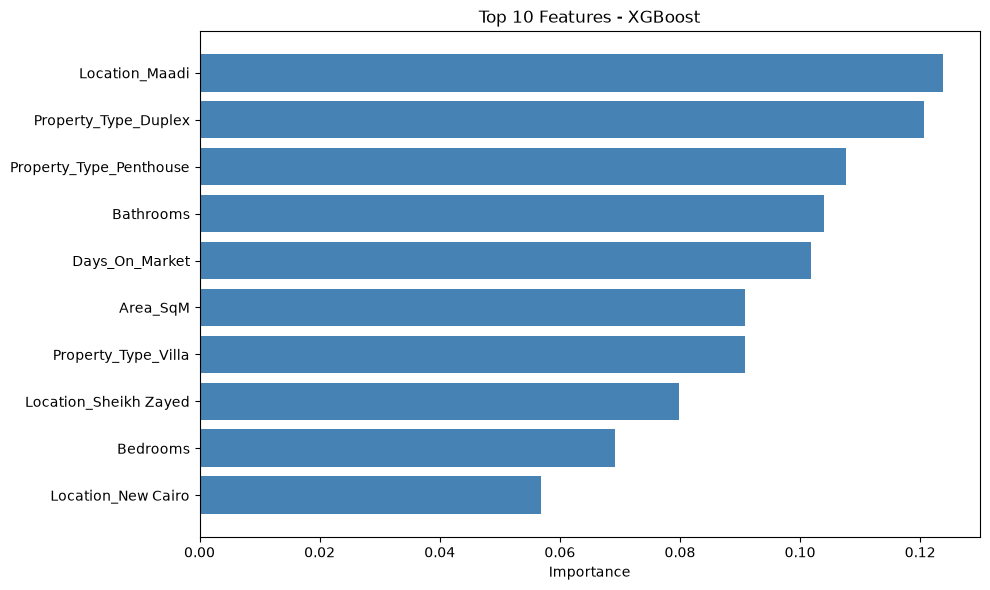

feature_importance.png saved

 results_adel.csv saved
           Model           MAE          RMSE        R2
0  Random Forest  3.309401e+06  4.004579e+06 -0.108610
1        XGBoost  3.759825e+06  4.410333e+06 -0.344646

ADEL - DONE WITH MODELS


In [1]:

# File: 02_adel_rf_xgb.ipynb
# Author: Mohamed Adel
# Models: Random Forest + XGBoost
# ------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("ADEL - Random Forest + XGBoost")
print("=" * 60)

# ----------------------------------------------
# 1. Load Data

df = pd.read_csv('../../1_Data/cleaned_data.csv')
print(f"\n Data Loaded: {df.shape}")

# ----------------------------------------------
# 2. Preprocessing

df = df.drop('Property_ID', axis=1)
df['Is_Sold'] = df['Is_Sold'].map({'Yes': 1, 'No': 0})
df_encoded = pd.get_dummies(df, columns=['Location', 'Property_Type'], drop_first=True)

# ----------------------------------------------
# 3. Features & Target


X = df_encoded.drop(['Price_EGP', 'Is_Sold'], axis=1)
y = df_encoded['Price_EGP']

print(f"Features: {X.columns.tolist()}")

# ----------------------------------------------
# 4. Split (random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# ----------------------------------------------
# 5. Random Forest

print("\n" + "=" * 60)
print("MODEL 3: Random Forest")
print("=" * 60)

rf = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print(f"MAE:  {rf_mae:,.2f}")
print(f"RMSE: {rf_rmse:,.2f}")
print(f"R²:   {rf_r2:.4f}")

# ----------------------------------------------
# 6. XGBoost

print("\n" + "=" * 60)
print("MODEL 4: XGBoost")
print("=" * 60)

xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2 = r2_score(y_test, xgb_pred)

print(f"MAE:  {xgb_mae:,.2f}")
print(f"RMSE: {xgb_rmse:,.2f}")
print(f"R²:   {xgb_r2:.4f}")

# ----------------------------------------------
# 7. Feature Importance

feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n" + "=" * 60)
print("FEATURE IMPORTANCE (XGBoost)")
print("=" * 60)
print(feat_imp.head(10))

plt.figure(figsize=(10, 6))
plt.barh(feat_imp['Feature'][:10], feat_imp['Importance'][:10], color='steelblue')
plt.xlabel('Importance')
plt.title('Top 10 Features - XGBoost')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("feature_importance.png saved")

# ----------------------------------------------
# 8. Save Results

results_adel = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'MAE': [rf_mae, xgb_mae],
    'RMSE': [rf_rmse, xgb_rmse],
    'R2': [rf_r2, xgb_r2]
})

results_adel.to_csv('results_adel.csv', index=False)
print("\n results_adel.csv saved")
print(results_adel)

print("\n" + "=" * 60)
print("ADEL - DONE WITH MODELS")
print("=" * 60)